# Predicting the Age of Autism Diagnosis

**Mission:** help parents of autistic children get an early diagnosis and connect them to qualified professionals and therapists.

**Use case:** many autistic children are diagnosed years after the first signs, and they miss the early-intervention window.
This model predicts **the age (in years) at which a child is diagnosed with autism** from the child's co-occurring conditions,
autism severity and family characteristics. **Early-intervention outreach teams** use the prediction to identify families
whose child is at risk of a late diagnosis and contact them first; **parents** use it as a prompt to seek an assessment early.

| | |
|---|---|
| **Target (y)** | Age when a doctor first told the parent the child had autism/ASD, in **years** |
| **Users** | Outreach and intake teams on the platform, and parents |
| **Data** | US National Survey of Children's Health (NSCH) 2022 and 2024, public-use files from the [US Census Bureau](https://www.census.gov/programs-surveys/nsch/data/datasets.html) |
| **Success metric** | Test RMSE at least 15% below a baseline that always predicts the mean age |

## 1. Setup

In [1]:
import io
import zipfile
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load the data
The NSCH is a yearly survey of US parents about their children's health, run by the US Census Bureau.
Each public-use file has one row per child and over 450 columns. We download the 2022 and 2024 files,
keep only **children whose parent was told they have autism**, and keep the columns relevant to our use case.

In [2]:
NSCH_URLS = {
    2022: "https://www2.census.gov/programs-surveys/nsch/datasets/2022/nsch_2022_topical_Stata.zip",
    2024: "https://www2.census.gov/programs-surveys/nsch/datasets/2024/nsch_2024_topical_Stata.zip",
}

RAW_COLUMNS = [
    "HHID",            # household ID (used only to check for duplicate children)
    "K2Q35A_1_YEARS",  # TARGET: age when first told the child had autism (years)
    "K2Q35C",          # autism severity: 1 mild, 2 moderate, 3 severe
    "K2Q31A",          # ever told: ADHD
    "K2Q33A",          # ever told: anxiety
    "K2Q32A",          # ever told: depression
    "K2Q36A",          # ever told: developmental delay
    "K2Q37A",          # ever told: speech or other language disorder
    "K2Q60A",          # ever told: intellectual disability
    "SC_SEX",          # child's sex
    "SC_RACE_R",       # child's race
    "SC_HISPANIC_R",   # child's Hispanic origin
    "FPL_I1",          # family income as % of the federal poverty line (50 to 400)
    "TOTKIDS_R",       # number of children in the household (1 to 4+)
    "INSTYPE",         # health insurance type
    "HIGRADE",         # highest education of the adults in the household
    "HHLANGUAGE",      # main language spoken at home
    "FAMILY_R",        # family structure
    "SC_AGE_YEARS",    # child's age at the time of the survey
]


def load_nsch_year(year, url):
    request = Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urlopen(request, timeout=180) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
    dta_name = next(name for name in archive.namelist() if name.endswith(".dta"))
    survey = pd.read_stata(archive.open(dta_name), convert_categoricals=False)
    survey.columns = survey.columns.str.upper()
    autism = survey[survey["K2Q35A"] == 1]
    print(f"{year}: {len(survey):,} children surveyed, {len(autism):,} ever told they have autism")
    return autism[RAW_COLUMNS].assign(SURVEY_YEAR=year)


raw = pd.concat([load_nsch_year(year, url) for year, url in NSCH_URLS.items()], ignore_index=True)
print("Combined:", raw.shape)

2022: 54,103 children surveyed, 1,908 ever told they have autism


2024: 51,375 children surveyed, 2,352 ever told they have autism
Combined: (4260, 20)


### Making the columns readable
The survey stores answers as numeric codes (for example `1 = Yes, 2 = No`). We rename the columns and replace
the codes with their labels from the official NSCH codebook, so the model, the API and the app all use readable values.
Survey answers that were skipped or refused are stored as missing (`NaN`).

In [3]:
YES_NO = {1: "yes", 2: "no"}
RACE = {1: "white", 2: "black", 3: "other", 4: "asian", 5: "other", 7: "multiracial"}

df = pd.DataFrame({
    "diagnosis_age": raw["K2Q35A_1_YEARS"],
    "severity": raw["K2Q35C"].map({1: "mild", 2: "moderate", 3: "severe"}),
    "adhd": raw["K2Q31A"].map(YES_NO),
    "anxiety": raw["K2Q33A"].map(YES_NO),
    "depression": raw["K2Q32A"].map(YES_NO),
    "developmental_delay": raw["K2Q36A"].map(YES_NO),
    "speech_disorder": raw["K2Q37A"].map(YES_NO),
    "intellectual_disability": raw["K2Q60A"].map(YES_NO),
    "sex": raw["SC_SEX"].map({1: "male", 2: "female"}),
    "race_ethnicity": np.where(raw["SC_HISPANIC_R"] == 1, "hispanic", raw["SC_RACE_R"].map(RACE)),
    "income_poverty_ratio": raw["FPL_I1"],
    "num_children": raw["TOTKIDS_R"],
    "insurance_type": raw["INSTYPE"].map({1: "public", 2: "private", 3: "public_and_private", 5: "uninsured"}),
    "parent_education": raw["HIGRADE"].map({1: "less_than_high_school", 2: "high_school", 3: "more_than_high_school"}),
    "home_language": raw["HHLANGUAGE"].map({1: "english", 2: "spanish", 3: "other"}),
    "family_structure": raw["FAMILY_R"].map({1: "two_parents", 2: "two_parents", 3: "two_parents", 4: "two_parents",
                                             5: "single_mother", 6: "single_father", 7: "grandparents", 8: "other"}),
    "current_age": raw["SC_AGE_YEARS"],
    "survey_year": raw["SURVEY_YEAR"],
    "household_id": raw["HHID"],
})
df["race_ethnicity"] = df["race_ethnicity"].replace("nan", np.nan)

print("Shape:", df.shape)
df.head()

Shape: (4260, 19)


,diagnosis_age,severity,adhd,anxiety,depression,developmental_delay,speech_disorder,intellectual_disability,sex,race_ethnicity,income_poverty_ratio,num_children,insurance_type,parent_education,home_language,family_structure,current_age,survey_year,household_id
0,3.0,moderate,no,no,no,yes,yes,no,female,white,92,3,public_and_private,more_than_high_school,english,two_parents,9,2022,22000329
1,4.0,moderate,no,no,NaN,yes,yes,no,male,asian,309,3,private,more_than_high_school,english,two_parents,4,2022,22000397
2,5.0,NaN,yes,yes,no,no,no,no,male,white,400,1,private,more_than_high_school,english,two_parents,8,2022,22000423
3,5.0,mild,no,no,no,yes,yes,no,female,white,400,3,private,more_than_high_school,english,two_parents,6,2022,22001191
4,5.0,mild,yes,no,no,no,no,no,male,white,134,3,private,more_than_high_school,english,NaN,11,2022,22001291


## 3. Inspect the data

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4260 entries, 0 to 4259
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis_age            3975 non-null   float64
 1   severity                 3986 non-null   str    
 2   adhd                     4256 non-null   str    
 3   anxiety                  4233 non-null   str    
 4   depression               4233 non-null   str    
 5   developmental_delay      4240 non-null   str    
 6   speech_disorder          4244 non-null   str    
 7   intellectual_disability  4249 non-null   str    
 8   sex                      4260 non-null   str    
 9   race_ethnicity           4260 non-null   str    
 10  income_poverty_ratio     4260 non-null   int16  
 11  num_children             4260 non-null   int8   
 12  insurance_type           4203 non-null   str    
 13  parent_education         4260 non-null   str    
 14  home_language            4229 non-n

In [5]:
df.describe()

,diagnosis_age,income_poverty_ratio,num_children,current_age,survey_year,household_id
count,3975.000000,4260.000000,4260.000000,4260.000000,4260.000000,4.260000e+03
mean,5.291824,263.792723,1.773709,10.395070,2023.104225,2.328814e+07
std,3.639570,129.694456,0.861895,4.487286,0.994670,1.006379e+06
min,1.000000,50.000000,1.000000,0.000000,2022.000000,2.200033e+07
25%,3.000000,145.000000,1.000000,7.000000,2022.000000,2.219688e+07
50%,4.000000,279.500000,2.000000,11.000000,2024.000000,2.403744e+07
75%,7.000000,400.000000,2.000000,14.000000,2024.000000,2.420797e+07
max,15.000000,400.000000,4.000000,17.000000,2024.000000,2.437404e+07


In [6]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nDuplicate children (same household ID and survey year):",
      df.duplicated(subset=["household_id", "survey_year"]).sum())

Missing values per column:
diagnosis_age              285
severity                   274
adhd                         4
anxiety                     27
depression                  27
developmental_delay         20
speech_disorder             16
intellectual_disability     11
sex                          0
race_ethnicity               0
income_poverty_ratio         0
num_children                 0
insurance_type              57
parent_education             0
home_language               31
family_structure            91
current_age                  0
survey_year                  0
household_id                 0
dtype: int64

Duplicate children (same household ID and survey year): 0


In [7]:
print("Rows without a diagnosis age:", df["diagnosis_age"].isnull().sum())
df = df.dropna(subset=["diagnosis_age"]).reset_index(drop=True)
print("Rows kept:", len(df))

Rows without a diagnosis age: 285
Rows kept: 3975


**Observations**
1. The two survey years give **4,260 children ever told they have autism**; **285 (6.7%) have no diagnosis age**, so those rows are removed, leaving **3,975 rows**. Missing values cannot be used as a target, and filling them would invent labels.
2. Most columns are **categorical** (stored as text after mapping the codes). Only `income_poverty_ratio`, `num_children` and `current_age` are numeric, so the categorical columns must be encoded before modelling.
3. `severity` is missing for **274 rows**, and `insurance_type`, `home_language` and `family_structure` for under 100 each. We **fill these in the preprocessing pipeline** with the most frequent training value rather than dropping rows, to keep the sample size.
4. There are **no duplicate children** (household ID plus survey year is unique). Rows with the same feature values are *not* removed, because they are different children who happen to share the same answers.
5. `income_poverty_ratio` is **limited to the range 50 to 400** by the survey, and `num_children` is capped at 4 ("4 or more").

## 4. Visualizations
### 4.1 Distribution of the target: age at autism diagnosis

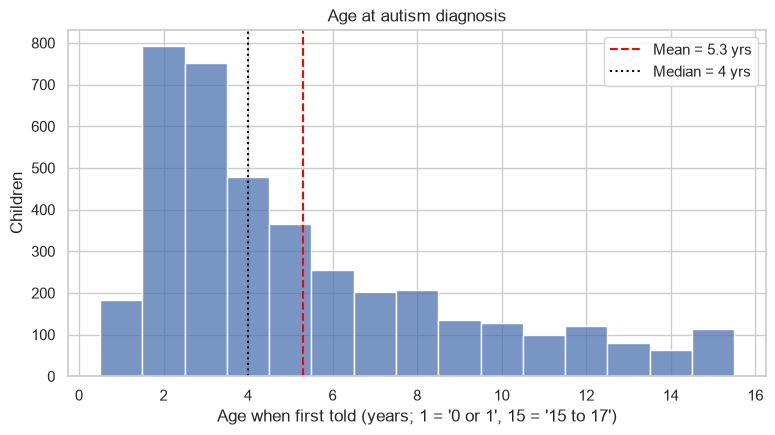

count    3975.00
mean        5.29
std         3.64
min         1.00
25%         3.00
50%         4.00
75%         7.00
max        15.00
Name: diagnosis_age, dtype: float64


In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(df["diagnosis_age"], bins=np.arange(0.5, 16.5, 1), ax=ax, color="#4C72B0")
ax.axvline(df["diagnosis_age"].mean(), color="red", linestyle="--", label=f"Mean = {df['diagnosis_age'].mean():.1f} yrs")
ax.axvline(df["diagnosis_age"].median(), color="black", linestyle=":", label=f"Median = {df['diagnosis_age'].median():.0f} yrs")
ax.set(title="Age at autism diagnosis", xlabel="Age when first told (years; 1 = '0 or 1', 15 = '15 to 17')", ylabel="Children")
ax.legend()
plt.show()

print(df["diagnosis_age"].describe().round(2))

**What it shows:** diagnosis age is **right-skewed**: most children are diagnosed at **2 to 4 years** (median 4), but there is a long tail of children diagnosed at school age and in adolescence (mean 5.3, standard deviation 3.6 years). The value 15 groups everyone diagnosed at 15 to 17.

**What we decided:** we keep the target in **years without a log transform**, so the error (RMSE) stays in years and is easy for users to understand. Because of the long tail, the 3.6-year standard deviation is the error a model that always guesses the mean would make (our **baseline**), and late-diagnosed children are exactly the group our use case needs to identify, so we keep them rather than treating them as outliers.

### 4.2 Correlation heatmap
To include the categorical columns, we temporarily code them as numbers: `yes = 1, no = 0`,
`severity` as 1 (mild) to 3 (severe), and `sex` as 1 for male. `current_age` is included to check whether it leaks information about the target.

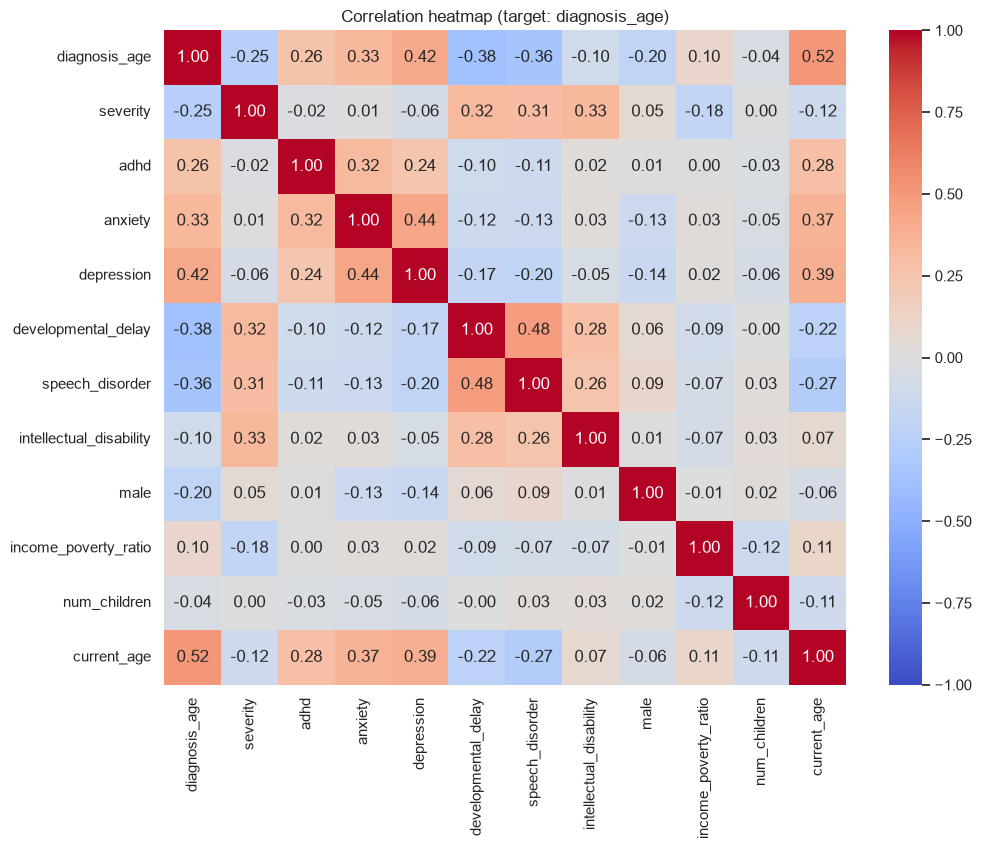

Correlation with diagnosis_age:
current_age                0.515
depression                 0.417
developmental_delay       -0.382
speech_disorder           -0.358
anxiety                    0.334
adhd                       0.265
severity                  -0.253
male                      -0.197
intellectual_disability   -0.101
income_poverty_ratio       0.095
num_children              -0.041
Name: diagnosis_age, dtype: float64


In [9]:
numeric_view = pd.DataFrame({
    "diagnosis_age": df["diagnosis_age"],
    "severity": df["severity"].map({"mild": 1, "moderate": 2, "severe": 3}),
    "adhd": df["adhd"].map({"yes": 1, "no": 0}),
    "anxiety": df["anxiety"].map({"yes": 1, "no": 0}),
    "depression": df["depression"].map({"yes": 1, "no": 0}),
    "developmental_delay": df["developmental_delay"].map({"yes": 1, "no": 0}),
    "speech_disorder": df["speech_disorder"].map({"yes": 1, "no": 0}),
    "intellectual_disability": df["intellectual_disability"].map({"yes": 1, "no": 0}),
    "male": (df["sex"] == "male").astype(int),
    "income_poverty_ratio": df["income_poverty_ratio"],
    "num_children": df["num_children"],
    "current_age": df["current_age"],
})

corr = numeric_view.corr()
fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation heatmap (target: diagnosis_age)")
plt.show()

print("Correlation with diagnosis_age:")
print(corr["diagnosis_age"].drop("diagnosis_age").sort_values(key=abs, ascending=False).round(3))

**What it shows:** the conditions a child already has are the strongest signals. **Developmental delay (-0.38)** and **speech disorder (-0.36)** go with *earlier* diagnosis, while **anxiety (+0.33)**, **ADHD (+0.26)** and **depression (+0.42)** go with *later* diagnosis. **More severe autism (-0.25)** and **being male (-0.20)** are linked to earlier diagnosis. Income (+0.10) and number of children (-0.04) are only weakly related. **`current_age` has the highest correlation (+0.52)**, and the predictors are only moderately correlated with each other (highest: developmental delay and speech disorder, 0.48), so collinearity is not a serious problem.

**What we decided:** we keep the condition, severity and sex features as the core of the model. The high correlation of `current_age` is a warning sign of leakage, which we check in Section 5.1. `num_children` is dropped because it has almost no relationship with the target.

### 4.3 Average diagnosis age by co-occurring condition and family characteristic

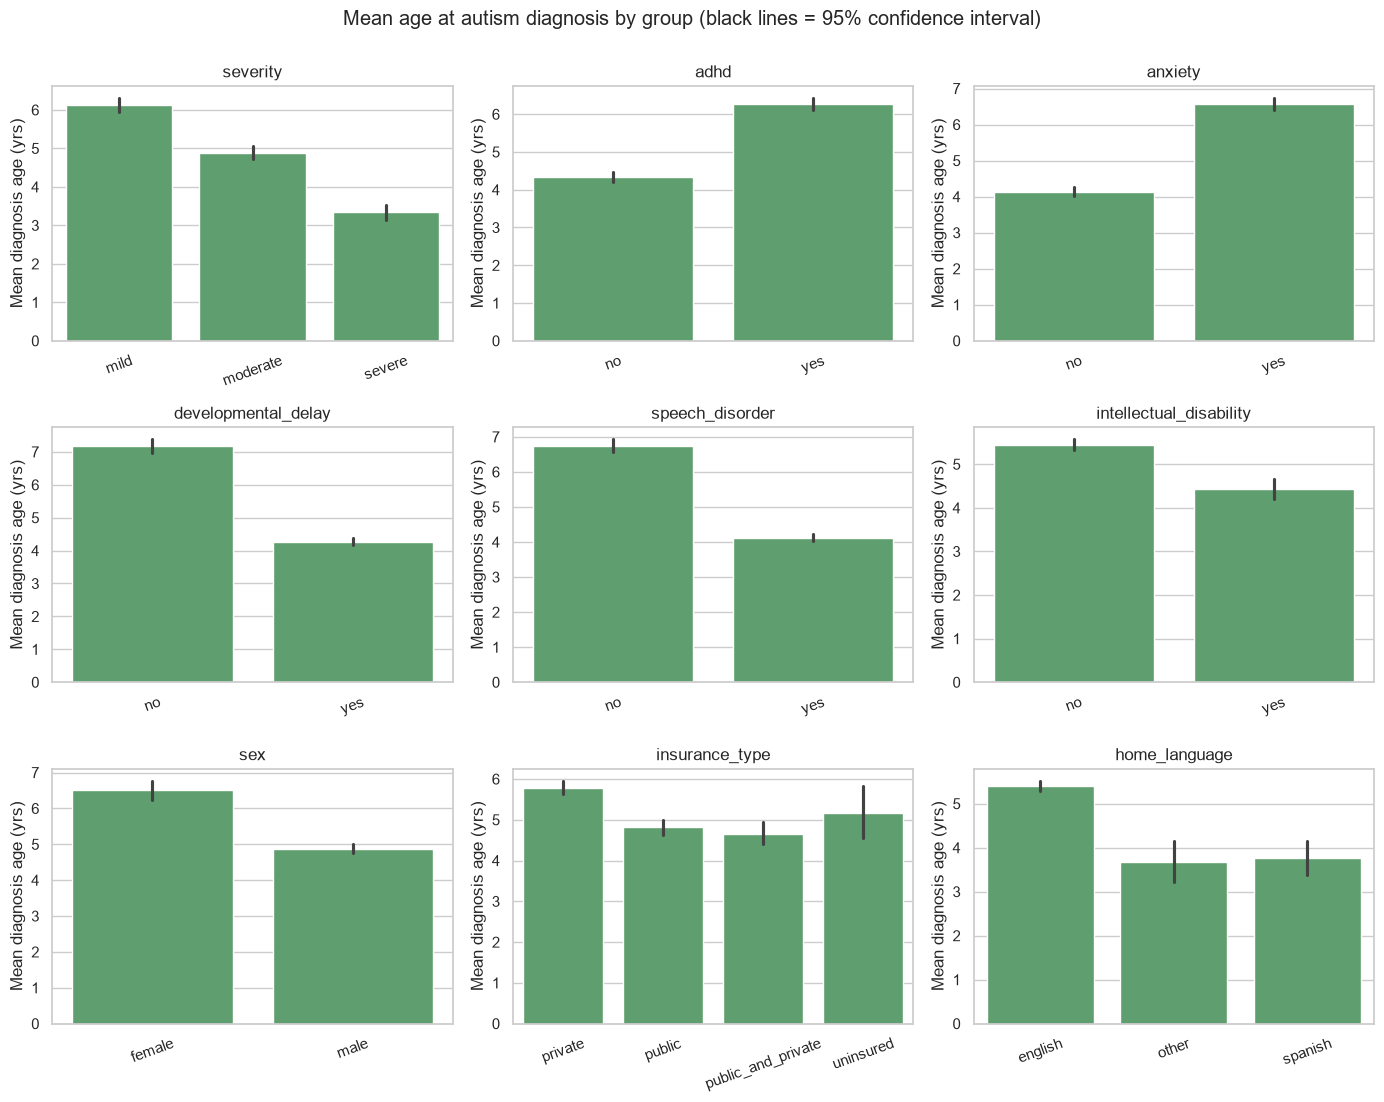

In [10]:
group_columns = ["severity", "adhd", "anxiety", "developmental_delay", "speech_disorder",
                 "intellectual_disability", "sex", "insurance_type", "home_language"]

fig, axes = plt.subplots(3, 3, figsize=(14, 11))
for ax, column in zip(axes.ravel(), group_columns):
    order = sorted(df[column].dropna().unique())
    sns.barplot(data=df, x=column, y="diagnosis_age", order=order, ax=ax, color="#55A868", errorbar=("ci", 95))
    ax.set(title=column, xlabel="", ylabel="Mean diagnosis age (yrs)")
    ax.tick_params(axis="x", rotation=20)
fig.suptitle("Mean age at autism diagnosis by group (black lines = 95% confidence interval)", y=1.0)
plt.tight_layout()
plt.show()

**What it shows:** the differences are large and the confidence intervals are narrow. Children with **ADHD or anxiety** are diagnosed about **2 years later** (6.3 and 6.6 vs about 4.2 years), consistent with autism being overlooked when another condition explains the behaviour. Children with **developmental delay or speech disorders** are diagnosed about **2.5 to 3 years earlier**, because these are visible early signs. **Girls** are diagnosed about **1.6 years later than boys** (6.5 vs 4.9), and **mild** autism about **3 years later than severe** (6.1 vs 3.3). Children in **privately insured** and **English-speaking** homes are diagnosed somewhat later on average, while the uninsured group is small and its interval is wide.

**What we decided:** all nine of these features are kept. The condition, severity and sex features carry most of the signal. `insurance_type` and `home_language` show smaller differences but are kept because access to care is central to our mission (connecting families to professionals), and the outreach team needs to see their effect.

### 4.4 Distribution of the numeric features

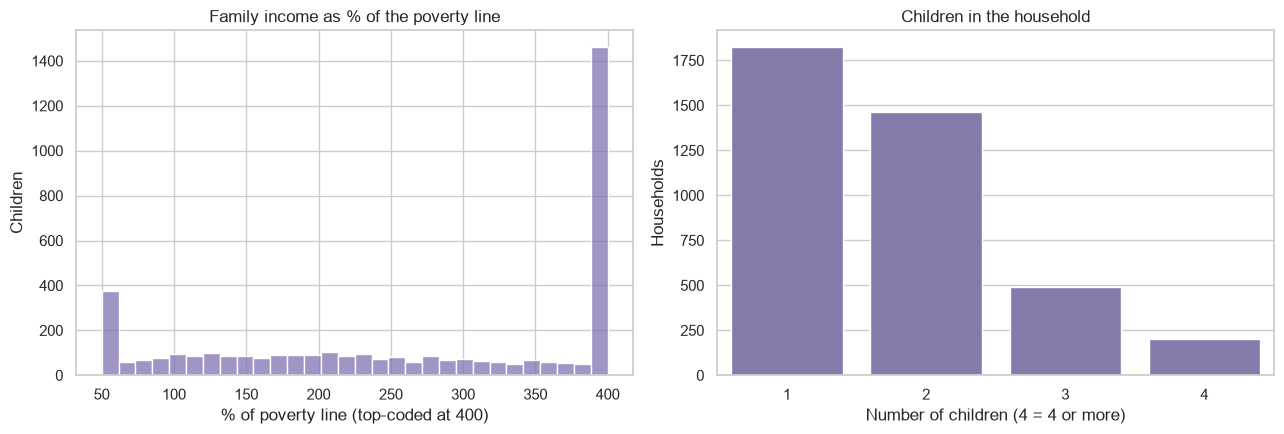

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df["income_poverty_ratio"], bins=30, ax=axes[0], color="#8172B2")
axes[0].set(title="Family income as % of the poverty line", xlabel="% of poverty line (top-coded at 400)", ylabel="Children")
sns.countplot(x=df["num_children"], ax=axes[1], color="#8172B2")
axes[1].set(title="Children in the household", xlabel="Number of children (4 = 4 or more)", ylabel="Households")
plt.tight_layout()
plt.show()

**What it shows:** `income_poverty_ratio` is **limited at both ends**: about a third of families are at the cap of **400% or more** of the poverty line and several hundred are at the floor of **50% or less**, with the rest spread evenly in between. `num_children` is mostly 1 or 2.

**What we decided:** the scale of income (50 to 400) is much larger than the 0/1 encoded features, so we **standardize** it so that no feature dominates gradient descent just because of its units. We keep it as our numeric input, since family income is a known barrier to getting an assessment. `num_children` is dropped (correlation -0.04).

## 5. Feature engineering
### 5.1 Checking for leakage: current age and depression
A child cannot have been diagnosed at an age older than they are now, so `current_age` puts an upper limit on the
target. Below we check how strongly it, and the conditions that tend to appear in older children, are tied to current age.

In [12]:
print("Correlation of current_age with diagnosis_age:", round(df["current_age"].corr(df["diagnosis_age"]), 3))
print("\nMean current age (years) of children with and without each condition:")
condition_columns = ["adhd", "anxiety", "depression", "developmental_delay", "speech_disorder", "intellectual_disability"]
print(pd.DataFrame({col: df.groupby(col)["current_age"].mean() for col in condition_columns}).T.round(1))

Correlation of current_age with diagnosis_age: 0.515

Mean current age (years) of children with and without each condition:
                           no   yes
adhd                      9.1  11.6
anxiety                   8.8  12.1
depression                9.5  13.8
developmental_delay      11.7   9.6
speech_disorder          11.7   9.3
intellectual_disability  10.2  11.0


**Result:** `current_age` correlates **+0.52** with the target. This is mostly *mechanical*: a 5-year-old cannot have been diagnosed at 10, so older children are the only ones who can have late diagnoses. The model would learn "older children have later diagnoses", which looks accurate but is useless for our users, because outreach teams want to flag a child **before** a late diagnosis happens. **`current_age` is therefore dropped.**

**Depression** behaves the same way: children with depression are on average **13.8 years old** vs 9.5 without, because depression is usually diagnosed in adolescence. Its high correlation with diagnosis age (+0.42) mostly reflects the child's current age, so **`depression` is also dropped**. ADHD and anxiety are also more common in older children (11.6 and 12.1 years), but they are typically identified in early school years and are well-documented reasons why autism is recognised later, so we keep them and note this as a limitation.

### 5.2 Columns dropped and features kept

In [13]:
NUMERIC_FEATURES = ["income_poverty_ratio"]
CATEGORICAL_FEATURES = ["severity", "adhd", "anxiety", "developmental_delay", "speech_disorder",
                        "intellectual_disability", "sex", "insurance_type", "home_language"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET = "diagnosis_age"

dropped = [col for col in df.columns if col not in FEATURES + [TARGET]]
print("Dropped columns:", dropped)
print(f"Kept {len(FEATURES)} input features:", FEATURES)

Dropped columns: ['depression', 'race_ethnicity', 'num_children', 'parent_education', 'family_structure', 'current_age', 'survey_year', 'household_id']
Kept 10 input features: ['income_poverty_ratio', 'severity', 'adhd', 'anxiety', 'developmental_delay', 'speech_disorder', 'intellectual_disability', 'sex', 'insurance_type', 'home_language']


To check these choices, we compare the 5-fold cross-validated RMSE of a simple linear regression using different
feature sets. The check uses **only the rows that will become the training set** (the same `random_state` as the split in Section 6),
so the test set plays no part in choosing features.

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

train_rows, _ = train_test_split(df.index, test_size=0.2, random_state=RANDOM_STATE)
check = df.loc[train_rows]


def cv_rmse(numeric, categorical):
    prep = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), numeric),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical),
    ])
    model = Pipeline([("prep", prep), ("model", LinearRegression())])
    scores = cross_val_score(model, check[numeric + categorical], check[TARGET], cv=5, scoring="neg_root_mean_squared_error")
    return -scores.mean()


feature_sets = {
    "Baseline: always predict the mean": None,
    "Kept 10 features": (NUMERIC_FEATURES, CATEGORICAL_FEATURES),
    "Kept + race, education, family, num_children": (NUMERIC_FEATURES + ["num_children"],
                                                    CATEGORICAL_FEATURES + ["race_ethnicity", "parent_education", "family_structure"]),
    "Kept + depression (age proxy)": (NUMERIC_FEATURES, CATEGORICAL_FEATURES + ["depression"]),
    "Kept + current_age (leakage)": (NUMERIC_FEATURES + ["current_age"], CATEGORICAL_FEATURES),
}
results = {name: (check[TARGET].std(ddof=0) if cols is None else cv_rmse(*cols)) for name, cols in feature_sets.items()}
pd.Series(results, name="CV RMSE (years)").round(3).to_frame()

,CV RMSE (years)
Baseline: always predict the mean,3.674
Kept 10 features,3.059
"Kept + race, education, family, num_children",3.070
Kept + depression (age proxy),2.956
Kept + current_age (leakage),2.834


**Result of the check:** the 10 kept features give a cross-validated RMSE of **3.06 years vs 3.67 for the baseline (about 17% lower)**, already above our 15% target before any tuning. Adding race, education, family structure and number of children makes it slightly *worse* (3.07). Adding `depression` (2.96) or `current_age` (2.83) lowers the error, but only because they tell the model how old the child is now (Section 5.1), so that improvement would not hold for the children our users need to flag.

**Columns dropped and why**

| Column | Reason |
|---|---|
| over 450 other survey columns | Not related to the use case (for example vaccination, sleep, sports and survey weights) |
| `current_age` | Leakage: diagnosis age can never be higher than current age (Section 5.1) |
| `depression` | Acts as a proxy for current age (mostly diagnosed in teenagers) |
| `num_children` | Almost no relationship with the target (correlation -0.04) |
| `race_ethnicity`, `parent_education`, `family_structure` | Added no accuracy once the conditions were included (CV RMSE 3.070 vs 3.059 without them), and race in particular could reinforce bias in an outreach tool |
| `survey_year`, `household_id` | Identifiers; they describe the survey, not the child |

**Features that matter most** (from the heatmap and group plots): `developmental_delay`, `speech_disorder`, `anxiety`, `adhd`, `severity` and `sex`. The final model uses **10 input features**: 1 numeric (`income_poverty_ratio`) and 9 categorical. These are also the 10 fields the API and the mobile app will ask for.

## 6. Encode, split and standardize
1. `X` holds the 10 input features and `y` the diagnosis age.
2. We split the rows into **80% training and 20% test** data before any preprocessing is fitted.
3. A `ColumnTransformer` handles each column type:
   * **numeric** (`income_poverty_ratio`): fill missing values with the training median, then standardize.
   * **categorical** (the other 9): fill missing values with the most frequent training value, **one-hot encode** them into 0/1 columns,
     then standardize, so every model input has mean 0 and standard deviation 1.
4. The preprocessor is **fitted on the training set only** and then applied to the test set, so no information
   from the test set leaks into training. The same fitted preprocessor will be saved with the best model,
   so the API can accept the raw readable values (for example `"severe"`).

In [15]:
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

numeric_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ("scale", StandardScaler()),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, NUMERIC_FEATURES),
    ("cat", categorical_pipeline, CATEGORICAL_FEATURES),
])

X_train_t = preprocessor.fit_transform(X_train)   # learn medians, categories, means and stds from TRAIN only
X_test_t = preprocessor.transform(X_test)         # apply them to TEST without refitting

print("Train rows:", X_train.shape[0], " Test rows:", X_test.shape[0])
print("Model inputs after one-hot encoding:", X_train_t.shape[1])
print(list(preprocessor.get_feature_names_out()))
print("\nTrain means (should be ~0):", X_train_t.mean(axis=0).round(2))
print("Train stds  (should be ~1):", X_train_t.std(axis=0).round(2))

Train rows: 3180  Test rows: 795
Model inputs after one-hot encoding: 23
['num__income_poverty_ratio', 'cat__severity_mild', 'cat__severity_moderate', 'cat__severity_severe', 'cat__adhd_no', 'cat__adhd_yes', 'cat__anxiety_no', 'cat__anxiety_yes', 'cat__developmental_delay_no', 'cat__developmental_delay_yes', 'cat__speech_disorder_no', 'cat__speech_disorder_yes', 'cat__intellectual_disability_no', 'cat__intellectual_disability_yes', 'cat__sex_female', 'cat__sex_male', 'cat__insurance_type_private', 'cat__insurance_type_public', 'cat__insurance_type_public_and_private', 'cat__insurance_type_uninsured', 'cat__home_language_english', 'cat__home_language_other', 'cat__home_language_spanish']

Train means (should be ~0): [ 0. -0. -0.  0. -0.  0. -0.  0. -0.  0. -0.  0. -0.  0.  0. -0. -0.  0.
  0. -0.  0. -0. -0.]
Train stds  (should be ~1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


**Summary of the prepared data**
* **3,180 training rows and 795 test rows**, from 3,975 children.
* The 10 input features became **23 model inputs** after one-hot encoding (for example, `severity` became `severity_mild`, `severity_moderate` and `severity_severe`).
* After the preprocessing, every training column has **mean 0 and standard deviation 1**, which confirms the scaling worked. The test set was transformed with the *training* statistics only.

The data is now ready for training and comparing the four models.